# Report 1 — Denoising of low-cost sensors

## 1.3 Denoise the data (eigenfaces / TPB-D)

Each complete day is a vector in $\mathbb R^{24}$. The reference-station days form the "face database"
$\mathbf Y\in\mathbb R^{D\times M}$ ($D=24$). With $\boldsymbol\Psi$ the mean reference day and
$\hat{\mathbf Y}=\mathbf Y-\boldsymbol\Psi\mathbf 1^\top = \mathbf U\boldsymbol\Sigma\mathbf V^\top$, an LCS day $\mathbf x_i$ is denoised as

$$\tilde{\mathbf x}_i=\boldsymbol\Psi+\mathbf U_\kappa\mathbf U_\kappa^\top(\mathbf x_i-\boldsymbol\Psi).$$

**Evaluation protocol.** If the day being denoised is also in the reference database, its own reference profile lies in the
subspace and the RMSE is optimistic. The main results therefore use **leave-one-day-out (LOO)**: for every day $i$, the
subspace is built from the other $M-1=103$ reference days. The "in-sample" variant (all days in the database) is shown for comparison.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.grid": True, "grid.alpha": 0.3})
COL = {"RefSt": "#2a7f62", "MLR": "#d1495b", "SVR": "#3d5a98"}
hours = np.arange(24)

daily = pd.read_csv("daily_complete_days.csv", header=[0, 1], index_col=0, parse_dates=True)
Y  = daily["RefSt"].to_numpy().T          # D x M  (columns = days)
XS = {"MLR": daily["MLR"].to_numpy().T, "SVR": daily["SVR"].to_numpy().T}
D, M = Y.shape
print(f"D = {D} hours, M = {M} complete days")

def rmse(a, b): return float(np.sqrt(np.mean((a - b) ** 2)))
def r2(y, yhat): return float(1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2))

base = pd.DataFrame({s: {"RMSE": rmse(Y, X), "R2": r2(Y, X)} for s, X in XS.items()}).T
print("Calibration baseline on the complete days:"); base.round(3)

D = 24 hours, M = 104 complete days
Calibration baseline on the complete days:


,RMSE,R2
MLR,13.424,0.876
SVR,12.455,0.894


### SVD of the reference database

Singular values, explained variance and the first "eigen-days" (columns of $\mathbf U$).

Cumulative energy, k=1..6: [0.621 0.761 0.838 0.881 0.907 0.925]


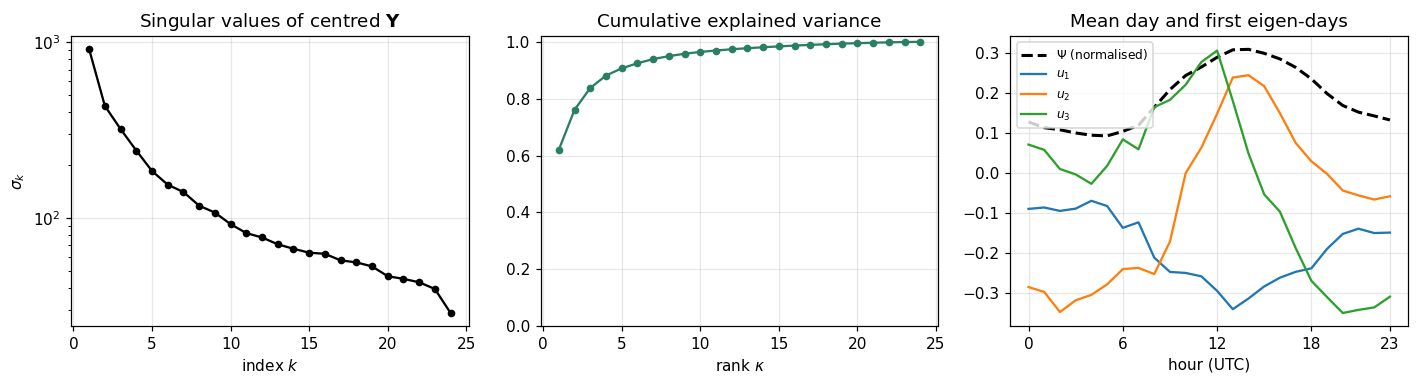

In [2]:
Psi = Y.mean(axis=1, keepdims=True)
U, s, Vt = np.linalg.svd(Y - Psi, full_matrices=False)
energy = np.cumsum(s**2) / np.sum(s**2)
print("Cumulative energy, k=1..6:", np.round(energy[:6], 3))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
axes[0].semilogy(np.arange(1, D + 1), s, "o-", color="k", ms=4)
axes[0].set(title="Singular values of centred $\\mathbf{Y}$", xlabel="index $k$", ylabel="$\\sigma_k$")
axes[1].plot(np.arange(1, D + 1), energy, "o-", color=COL["RefSt"], ms=4)
axes[1].set(title="Cumulative explained variance", xlabel="rank $\\kappa$", ylim=(0, 1.02))
axes[2].plot(hours, Psi.ravel() / np.linalg.norm(Psi), "k--", lw=2, label="$\\Psi$ (normalised)")
for k in range(3):
    axes[2].plot(hours, U[:, k], lw=1.5, label=f"$u_{k+1}$")
axes[2].set(title="Mean day and first eigen-days", xlabel="hour (UTC)", xticks=[0, 6, 12, 18, 23])
axes[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "1_3_svd.pdf", bbox_inches="tight"); plt.show()

### Denoising as a function of the rank $\kappa$

In [3]:
def denoise(X, Yref, k):
    """Project the columns of X onto the rank-k reference subspace (centred on the reference mean)."""
    psi = Yref.mean(axis=1, keepdims=True)
    Uk = np.linalg.svd(Yref - psi, full_matrices=False)[0][:, :k]
    return psi + Uk @ (Uk.T @ (X - psi))

def denoise_loo(X, Yref, k):
    out = np.empty_like(X)
    for i in range(X.shape[1]):
        keep = np.arange(X.shape[1]) != i
        out[:, [i]] = denoise(X[:, [i]], Yref[:, keep], k)
    return out

ks = np.arange(1, D + 1)
curves = {}
for name, X in XS.items():
    curves[(name, "LOO")]       = [rmse(Y, denoise_loo(X, Y, k)) for k in ks]
    curves[(name, "in-sample")] = [rmse(Y, denoise(X, Y, k)) for k in ks]
curves = pd.DataFrame(curves, index=ks)
k_opt = {name: int(curves[(name, "LOO")].idxmin()) for name in XS}
print("Optimal rank (LOO):", k_opt)
curves.round(2).head(12)

Optimal rank (LOO): {'MLR': 10, 'SVR': 8}


MLR              SVR          
      LOO in-sample    LOO in-sample
1   16.08     15.85  15.61     15.36
2   14.84     14.55  13.47     13.11
3   14.24     13.85  12.77     12.29
4   13.83     13.54  12.36     12.00
5   13.56     13.26  12.06     11.68
6   13.39     13.11  11.85     11.48
7   13.28     13.05  11.73     11.43
8   13.19     12.99  11.65     11.39
9   13.16     12.98  11.77     11.54
10  13.14     12.98  11.77     11.57
11  13.16     13.02  11.84     11.68
12  13.23     13.07  11.93     11.74

### Gavish–Donoho threshold

$\tilde\sigma = w(\beta)\,\sigma_{med}$ with $w(\beta)\approx0.56\beta^3-0.95\beta^2+1.82\beta+1.43$ and $\beta=D/M$.
$\kappa$ is the number of singular values above $\tilde\sigma$. Since $D<M$ here, $\beta = 24/104 \approx 0.23$.

beta = 0.231, w(beta) = 1.806, sigma_med = 73.99, threshold = 133.64  ->  kappa_Gavish = 7
kappa_Gavish across LOO folds: {7: 104}


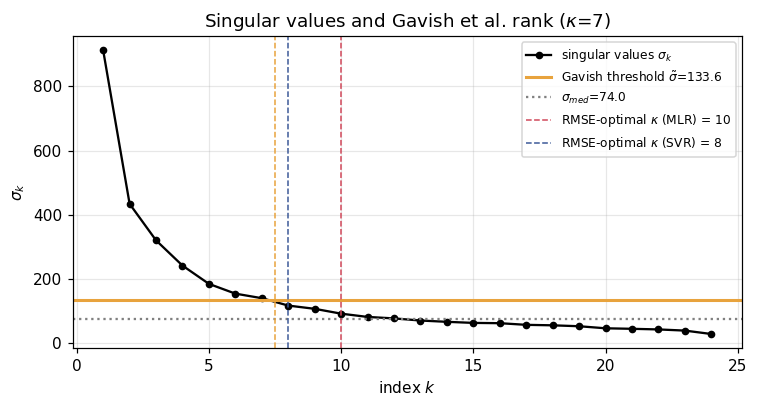

In [4]:
beta = D / M
w = 0.56 * beta**3 - 0.95 * beta**2 + 1.82 * beta + 1.43
sigma_thr = w * np.median(s)
k_gav = int(np.sum(s > sigma_thr))
print(f"beta = {beta:.3f}, w(beta) = {w:.3f}, sigma_med = {np.median(s):.2f}, threshold = {sigma_thr:.2f}  ->  kappa_Gavish = {k_gav}")

# LOO version: the threshold is recomputed on each M-1 database; report how stable it is
k_gav_loo = []
for i in range(M):
    Yi = np.delete(Y, i, axis=1)
    si = np.linalg.svd(Yi - Yi.mean(axis=1, keepdims=True), compute_uv=False)
    bi = D / (M - 1); wi = 0.56 * bi**3 - 0.95 * bi**2 + 1.82 * bi + 1.43
    k_gav_loo.append(int(np.sum(si > wi * np.median(si))))
print("kappa_Gavish across LOO folds:", pd.Series(k_gav_loo).value_counts().to_dict())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(ks, s, "o-", color="k", ms=4, label="singular values $\\sigma_k$")
ax.axhline(sigma_thr, color="#e8a33d", lw=2, label=f"Gavish threshold $\\tilde\\sigma$={sigma_thr:.1f}")
ax.axhline(np.median(s), color="grey", ls=":", label=f"$\\sigma_{{med}}$={np.median(s):.1f}")
ax.axvline(k_gav + 0.5, color="#e8a33d", ls="--", lw=1)
for name in XS:
    ax.axvline(k_opt[name], color=COL[name], ls="--", lw=1, label=f"RMSE-optimal $\\kappa$ ({name}) = {k_opt[name]}")
ax.set(xlabel="index $k$", ylabel="$\\sigma_k$", title=f"Singular values and Gavish et al. rank ($\\kappa$={k_gav})")
ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIG / "1_3_gavish.pdf", bbox_inches="tight"); plt.show()

### RMSE vs rank, with the calibration baseline and both selected ranks

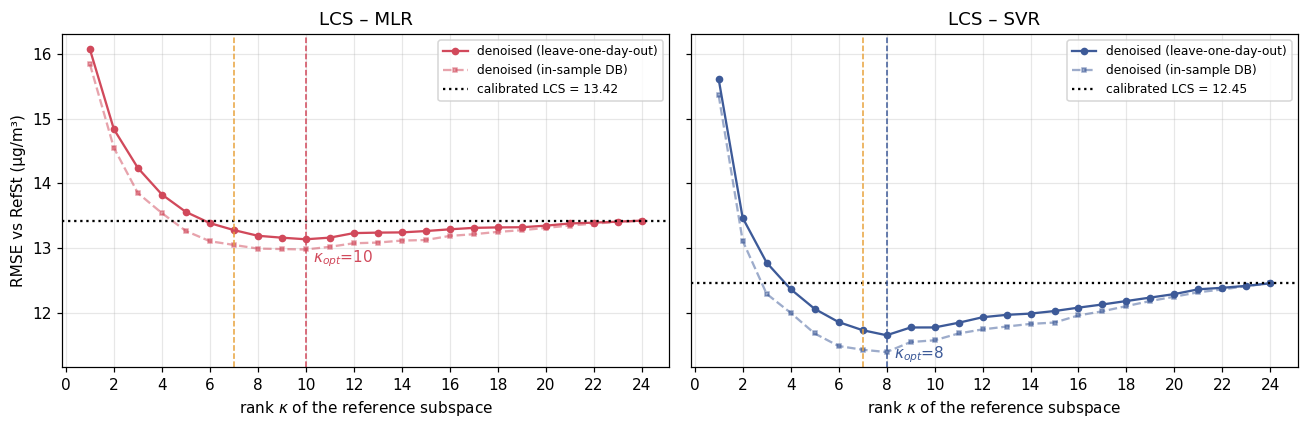

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, XS):
    ax.plot(ks, curves[(name, "LOO")], "o-", color=COL[name], ms=4, label="denoised (leave-one-day-out)")
    ax.plot(ks, curves[(name, "in-sample")], "s--", color=COL[name], ms=3, alpha=0.5, label="denoised (in-sample DB)")
    ax.axhline(base.loc[name, "RMSE"], color="k", ls=":", label=f"calibrated LCS = {base.loc[name,'RMSE']:.2f}")
    ax.axvline(k_opt[name], color=COL[name], ls="--", lw=1)
    ax.axvline(k_gav, color="#e8a33d", ls="--", lw=1)
    ax.annotate(f"$\\kappa_{{opt}}$={k_opt[name]}", (k_opt[name], curves[(name, "LOO")].min()),
                xytext=(5, -15), textcoords="offset points", color=COL[name])
    ax.set(title=f"LCS – {name}", xlabel="rank $\\kappa$ of the reference subspace", xticks=range(0, 25, 2))
    ax.legend(fontsize=8)
axes[0].set_ylabel("RMSE vs RefSt (µg/m³)")
fig.tight_layout(); fig.savefig(FIG / "1_3_rmse_vs_rank.pdf", bbox_inches="tight"); plt.show()

### Summary table

In [6]:
rows = []
for name, X in XS.items():
    rows.append({"sensor": name, "method": "calibrated (no denoising)", "kappa": "–", "RMSE": rmse(Y, X), "R2": r2(Y, X)})
    for label, k in [("TPB-D, RMSE-optimal kappa", k_opt[name]), ("TPB-D, Gavish kappa", k_gav)]:
        Xd = denoise_loo(X, Y, k)
        rows.append({"sensor": name, "method": label, "kappa": k, "RMSE": rmse(Y, Xd), "R2": r2(Y, Xd)})
summary = pd.DataFrame(rows)
summary["RMSE gain %"] = summary.groupby("sensor")["RMSE"].transform(lambda r: 100 * (1 - r / r.iloc[0]))
summary.to_csv("results_1_3_summary.csv", index=False)
summary.round(3)

,sensor,method,kappa,RMSE,R2,RMSE gain %
0,MLR,calibrated (no denoising),–,13.424,0.876,0.000
1,MLR,"TPB-D, RMSE-optimal kappa",10,13.135,0.882,2.150
2,MLR,"TPB-D, Gavish kappa",7,13.278,0.879,1.088
3,SVR,calibrated (no denoising),–,12.455,0.894,0.000
4,SVR,"TPB-D, RMSE-optimal kappa",8,11.650,0.907,6.459
5,SVR,"TPB-D, Gavish kappa",7,11.728,0.906,5.831


### Example days: before and after denoising (LOO, RMSE-optimal rank)

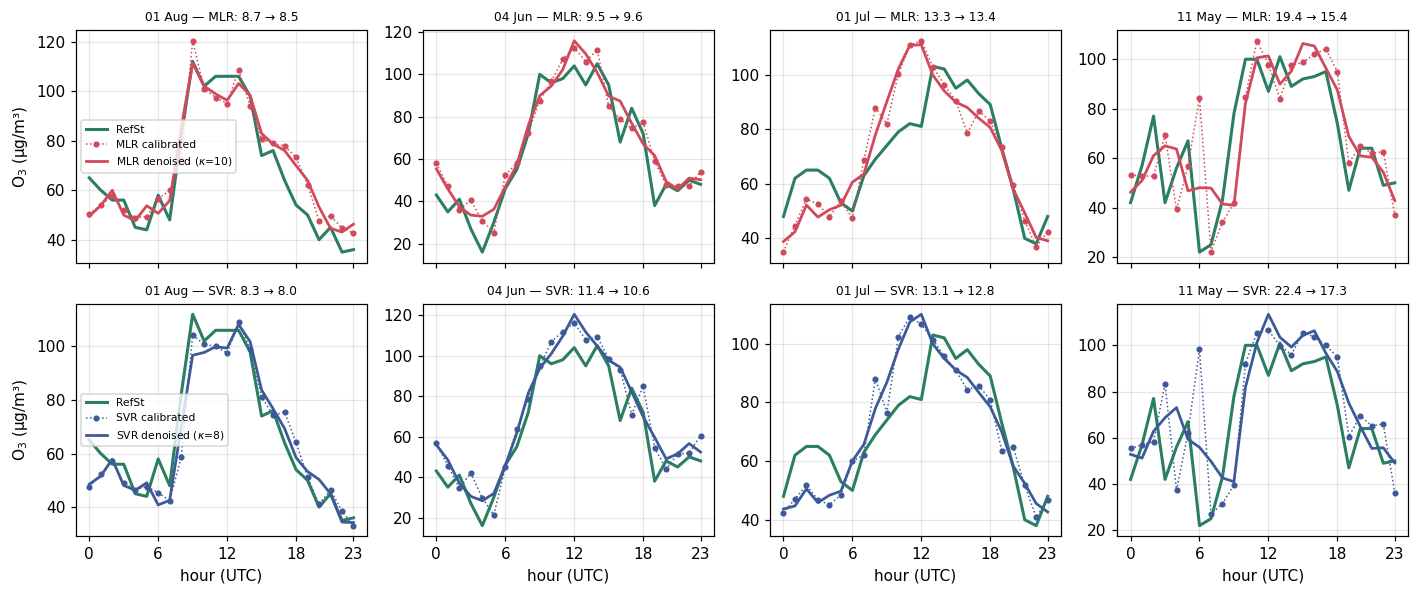

In [7]:
den = {name: denoise_loo(X, Y, k_opt[name]) for name, X in XS.items()}
day_err = np.sqrt(((XS["SVR"] - Y) ** 2).mean(axis=0))
pick = np.argsort(day_err)[np.linspace(10, M - 1, 4).astype(int)]   # moderate to worst days for SVR
dates = daily.index

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True)
for j, i in enumerate(pick):
    for r, name in enumerate(XS):
        ax = axes[r, j]
        ax.plot(hours, Y[:, i], color=COL["RefSt"], lw=2, label="RefSt")
        ax.plot(hours, XS[name][:, i], color=COL[name], lw=1, ls=":", marker=".", label=f"{name} calibrated")
        ax.plot(hours, den[name][:, i], color=COL[name], lw=1.8, label=f"{name} denoised ($\\kappa$={k_opt[name]})")
        ax.set_title(f"{dates[i]:%d %b} — {name}: {rmse(Y[:, i], XS[name][:, i]):.1f} → {rmse(Y[:, i], den[name][:, i]):.1f}", fontsize=8)
        ax.set_xticks([0, 6, 12, 18, 23])
for r in range(2):
    axes[r, 0].set_ylabel("O$_3$ (µg/m³)"); axes[r, 0].legend(fontsize=7)
for ax in axes[1]: ax.set_xlabel("hour (UTC)")
fig.tight_layout(); fig.savefig(FIG / "1_3_examples.pdf", bbox_inches="tight"); plt.show()

### Per-day RMSE improvement

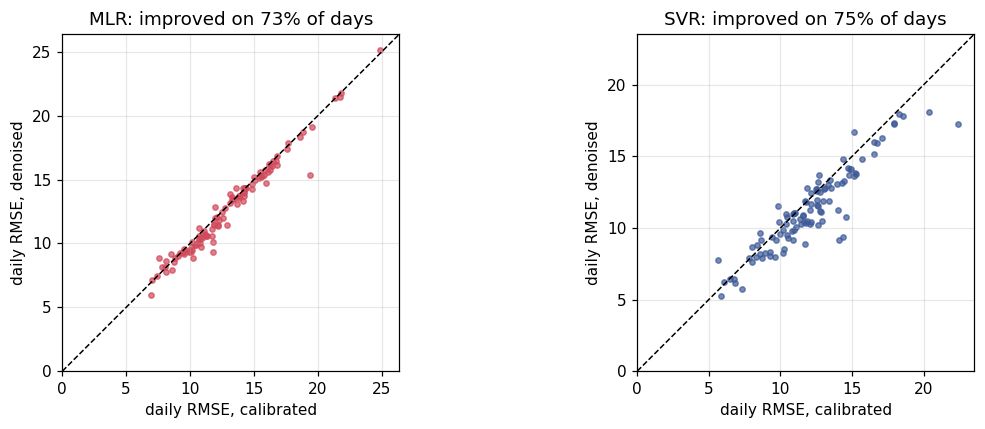

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, name in zip(axes, XS):
    before = np.sqrt(((XS[name] - Y) ** 2).mean(axis=0))
    after = np.sqrt(((den[name] - Y) ** 2).mean(axis=0))
    ax.scatter(before, after, s=12, color=COL[name], alpha=0.7)
    lim = [0, max(before.max(), after.max()) * 1.05]
    ax.plot(lim, lim, "k--", lw=1)
    ax.set(xlim=lim, ylim=lim, xlabel="daily RMSE, calibrated", ylabel="daily RMSE, denoised",
           title=f"{name}: improved on {np.mean(after < before):.0%} of days")
    ax.set_aspect("equal")
fig.tight_layout(); fig.savefig(FIG / "1_3_per_day.pdf", bbox_inches="tight"); plt.show()

### Observations (draft, to refine)

- The reference daily profiles are strongly low-rank: a few eigen-days carry most of the variance (mean day + amplitude + phase/shape terms).
- Projecting onto the RMSE-optimal subspace reduces RMSE for both sensors (see table). The gain comes from removing the components of
  the calibrated signal that are not consistent with any plausible reference day shape.
- Too small $\kappa$ forces every day onto a few shapes (bias); too large $\kappa$ re-admits the sensor noise. $\kappa=24$ is the identity, i.e. the calibrated signal.
- The Gavish et al. rank is obtained without the co-located sensor ground truth; compare it with the RMSE-optimal $\kappa$ in the table.